### **`Transfer Learning and Fine-Tuning with BERT`**

## Objective
Understand and implement transfer learning and fine-tuning using a pretrained BERT model for text classification.

### Experiments
1. Explore BERT architecture and tokenizer.
2. Perform feature extraction using frozen BERT.
3. Perform full fine-tuning.
4. Evaluate and compare model performance.

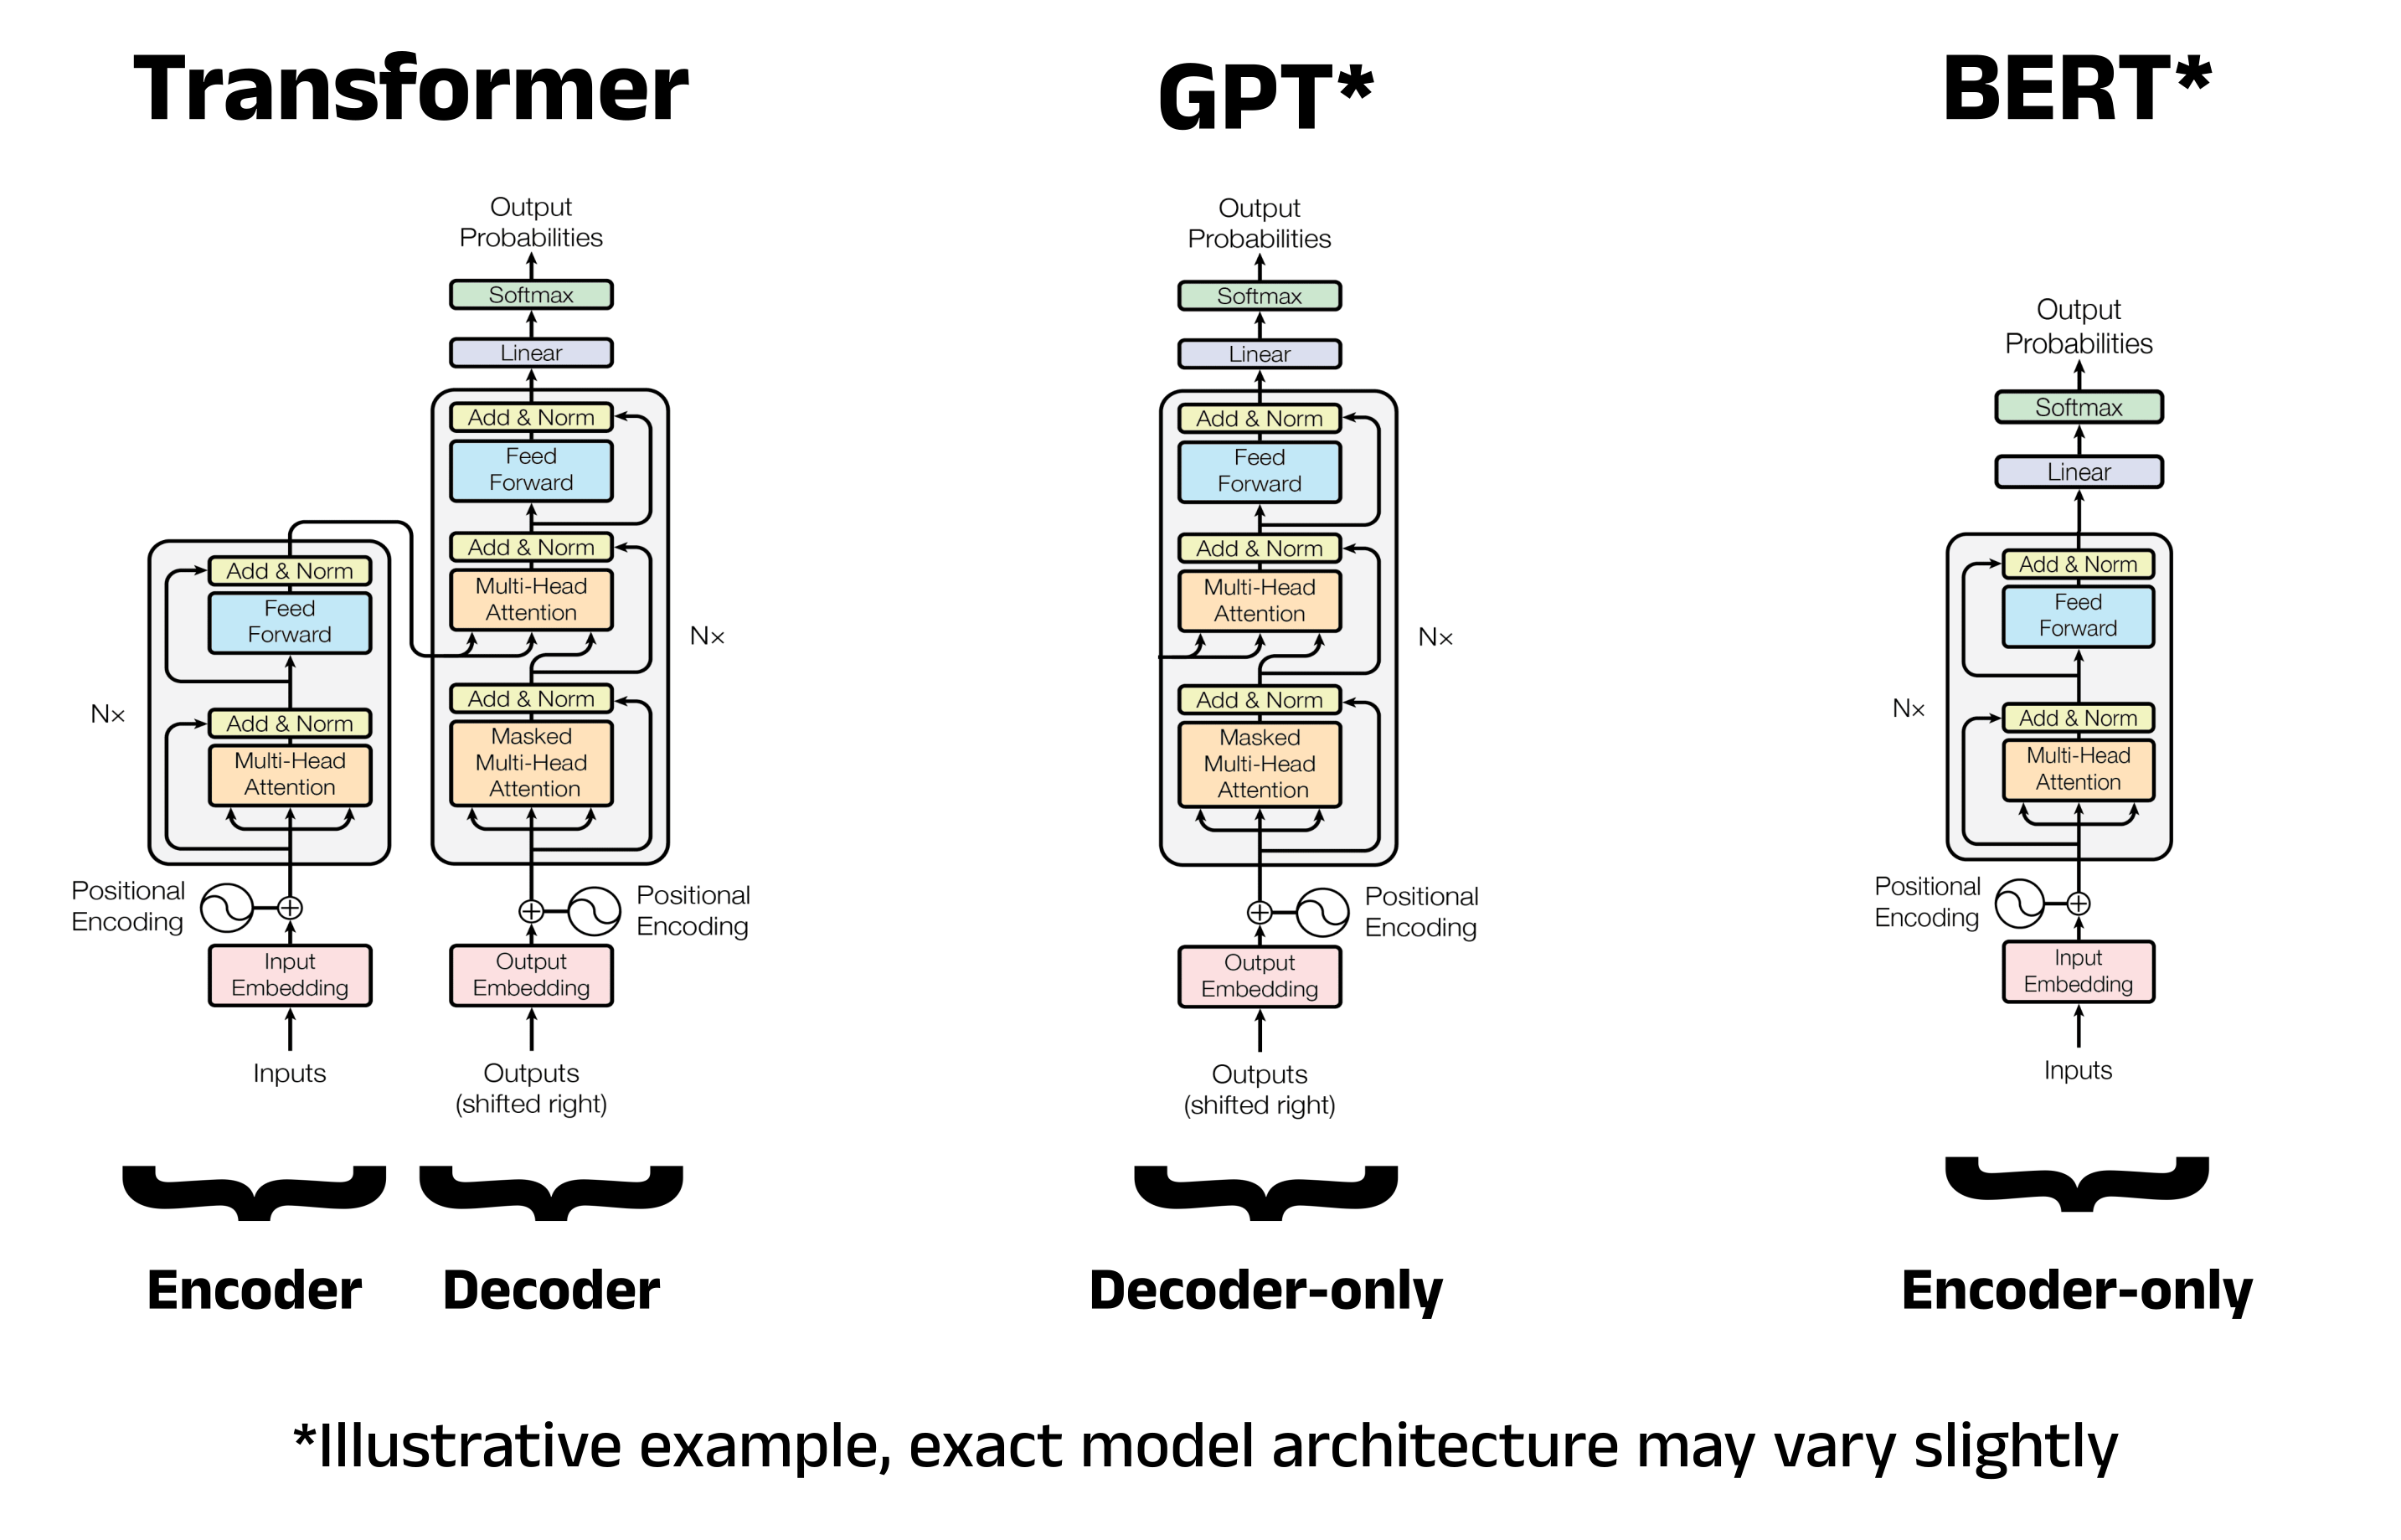

In [1]:

# ==================================================
# 1. BASIC LIBRARIES
# ==================================================
import os                          # File and folder handling
import numpy as np                 # Numerical operations
import matplotlib.pyplot as plt    # Data visualization

# ==================================================
# 2. PYTORCH LIBRARIES
# ==================================================
import torch                       # Deep learning framework
import torch.nn as nn              # Neural network layers
from torch.utils.data import DataLoader  # Load data in batches

# ==================================================
# 3. DATASET LOADING
# ==================================================
from datasets import load_dataset  # Load Hugging Face datasets

# ==================================================
# 4. BERT MODELS AND TOKENIZERS
# ==================================================
from transformers import (
    BertTokenizer,                  # BERT-specific tokenizer
    BertModel,                      # Pretrained BERT encoder
    BertForSequenceClassification,  # BERT with classification head
    AutoTokenizer,                  # Automatically load tokenizer
    AutoModelForSequenceClassification  # Automatically load classifier
)

# ==================================================
# 5. MODEL TRAINING
# ==================================================
from transformers import (
    Trainer,                        # Model training and evaluation
    TrainingArguments,              # Training configuration
    DataCollatorWithPadding         # Dynamic batch padding
)

# ==================================================
# 6. MODEL EVALUATION
# ==================================================
from sklearn.metrics import (
    accuracy_score,                 # Calculate accuracy
    classification_report,          # Precision, recall, and F1-score
    confusion_matrix                # Analyze classification errors
)

# ==================================================
# 7. DEVICE CONFIGURATION
# ==================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Using Device: {device}")


Using Device: cuda


In [2]:
from datasets import load_dataset, ClassLabel

# Load the original Emotion dataset
dataset = load_dataset("dair-ai/emotion", "split", split="train")

# Keep only sadness, joy, and anger
dataset = dataset.filter(lambda x: x["label"] in [0, 1, 3])

# Remap original labels to three classes
label_map = {0: 0, 1: 1, 3: 2}
dataset = dataset.map(lambda x: {"label": label_map[x["label"]]})

# Assign new class names
dataset = dataset.cast_column(
    "label",
    ClassLabel(names=["sadness", "joy", "anger"])
)

# Verify dataset
print(dataset)
print("Classes:", dataset.features["label"].names)

Dataset({
    features: ['text', 'label'],
    num_rows: 12187
})
Classes: ['sadness', 'joy', 'anger']


In [3]:
# Split dataset into 80% training and 20% testing
split_data = dataset.train_test_split(
    test_size=0.2,
    seed=42,
    stratify_by_column="label"
)

# Separate training and testing datasets
train_data = split_data["train"]
test_data = split_data["test"]

# Display dataset sizes
print(f"Training Samples: {len(train_data)}")
print(f"Testing Samples: {len(test_data)}")

# Display class names
print("Classes:", train_data.features["label"].names)

Training Samples: 9749
Testing Samples: 2438
Classes: ['sadness', 'joy', 'anger']


In [4]:
# Load the pretrained BERT tokenizer
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

# Test tokenizer with a sample sentence
text = "I am very happy today."

# Convert text into BERT tokens
tokens = tokenizer.tokenize(text)

print("Original Text:", text)
print("Tokens:", tokens)
print("Token IDs:", tokenizer.convert_tokens_to_ids(tokens))

Original Text: I am very happy today.
Tokens: ['i', 'am', 'very', 'happy', 'today', '.']
Token IDs: [1045, 2572, 2200, 3407, 2651, 1012]


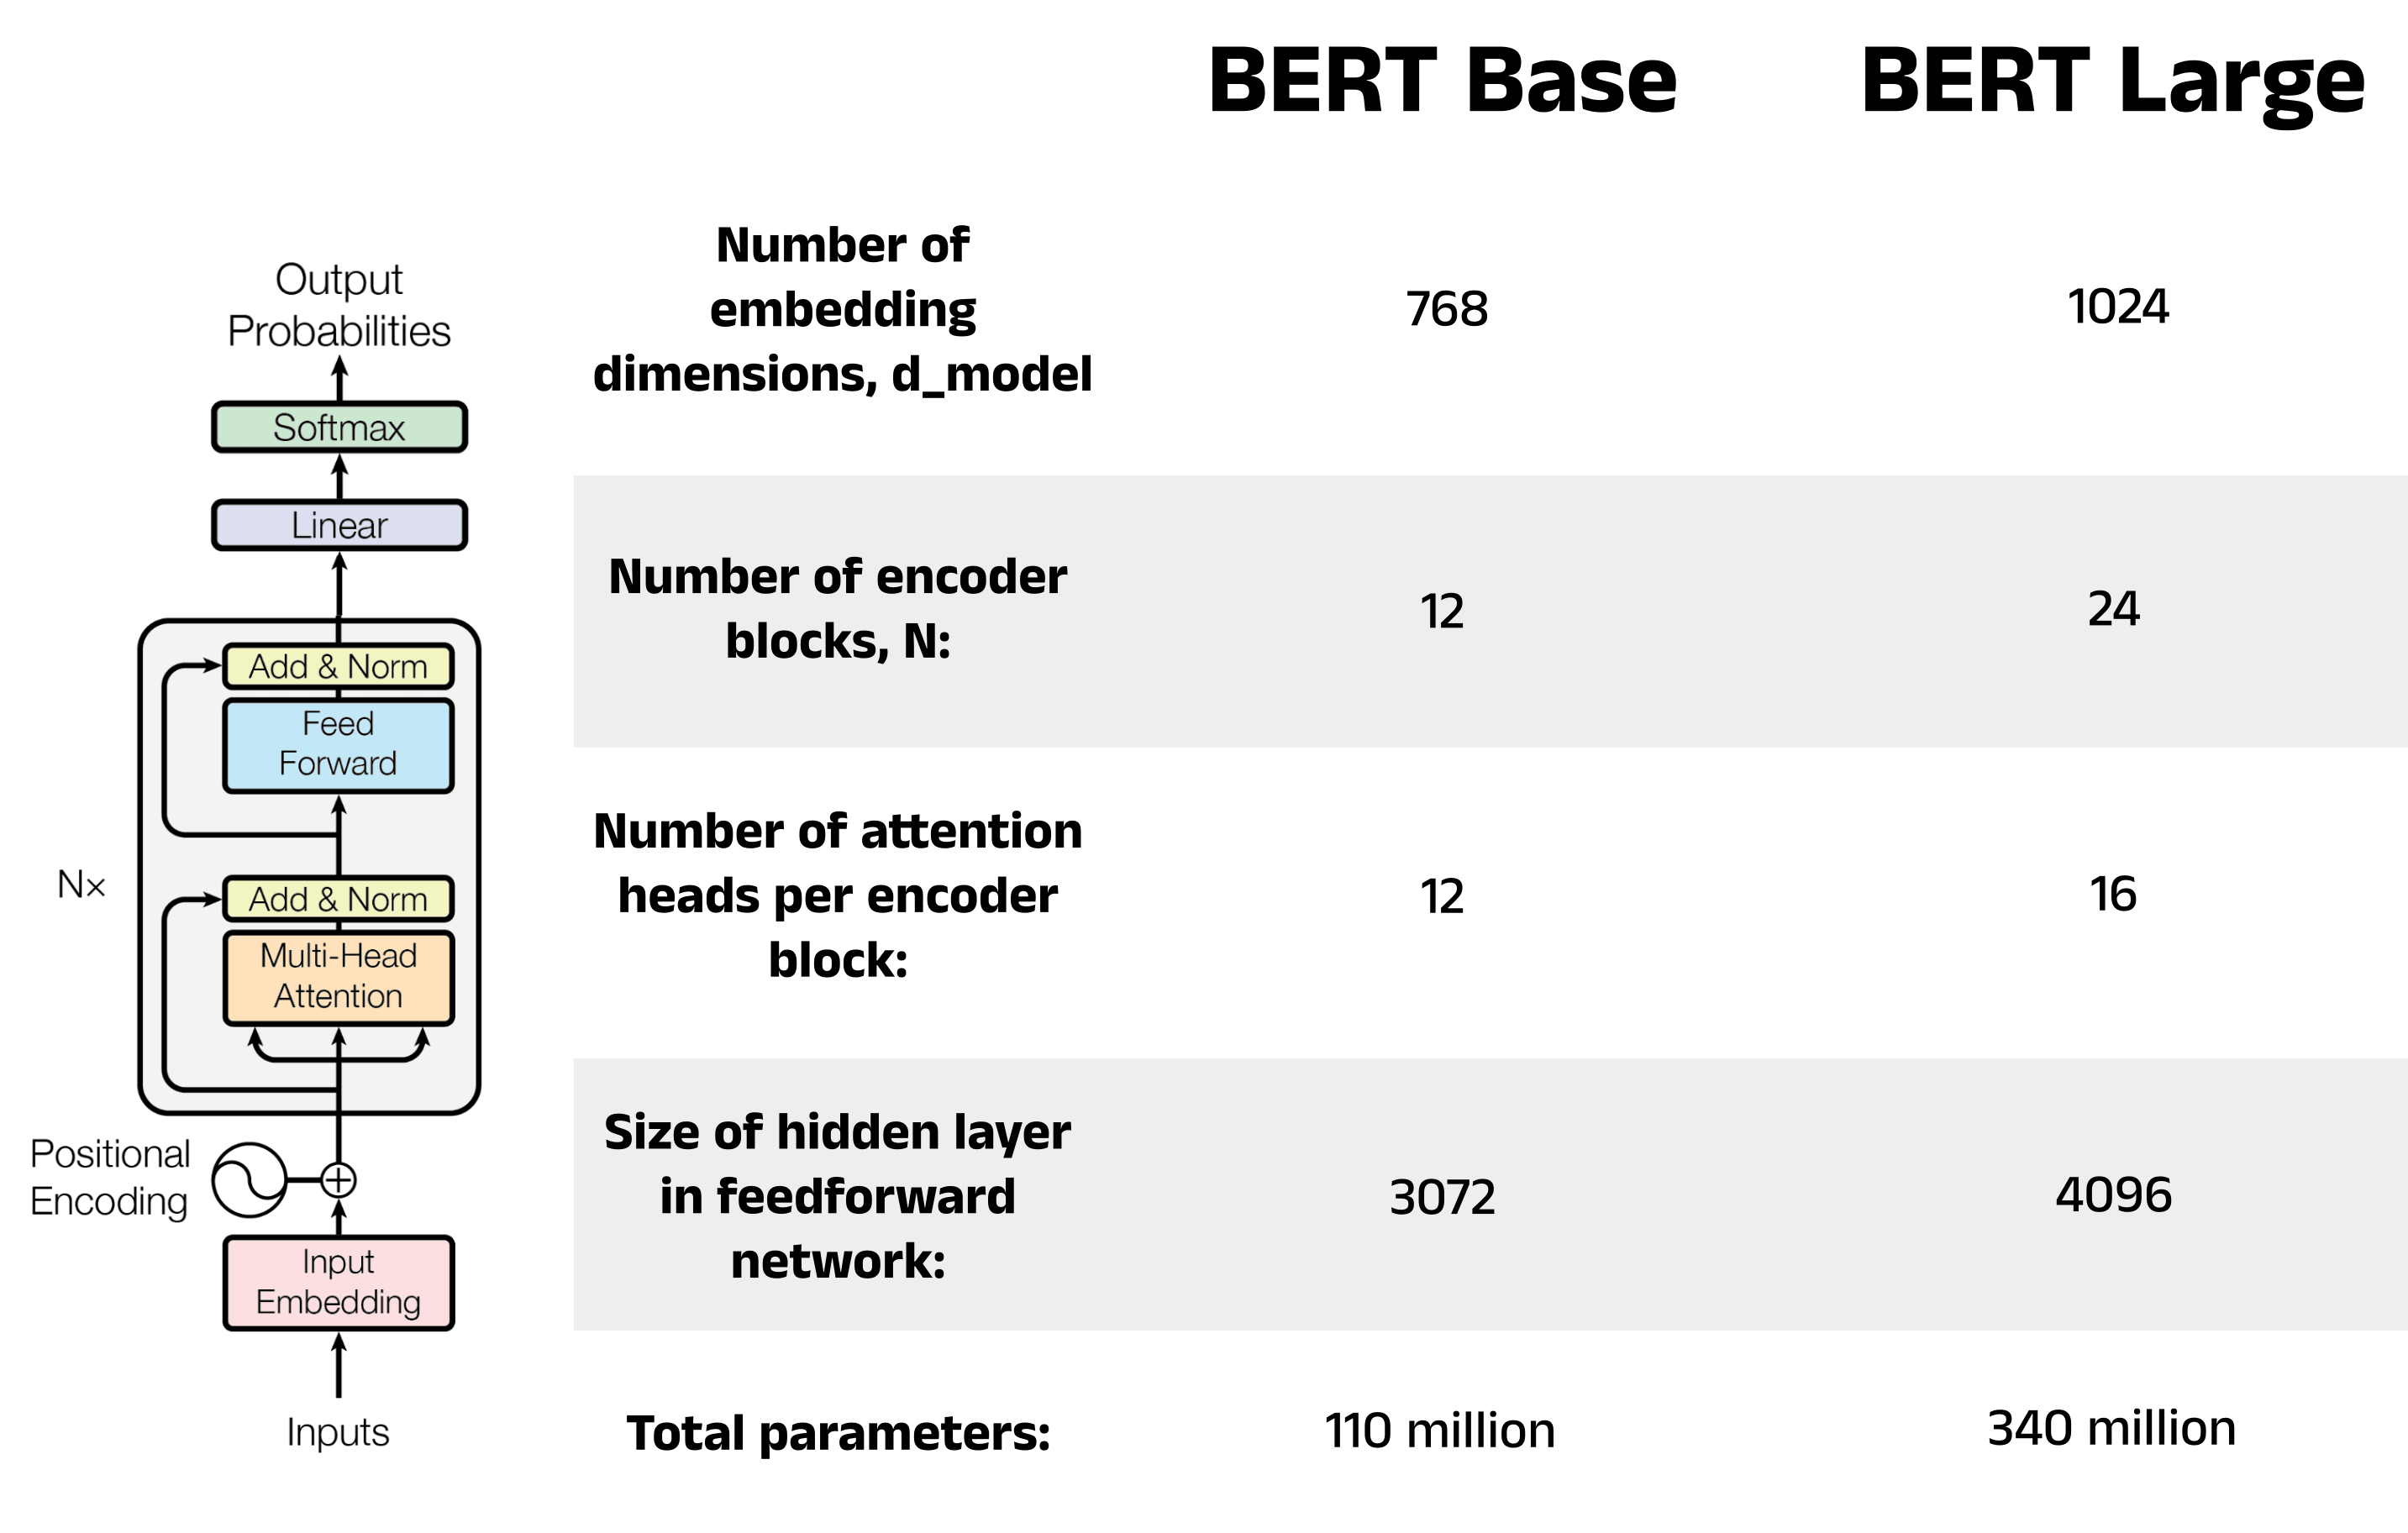

In [5]:
# Convert text into BERT tokens
def tokenize(batch):
    return tokenizer(
        batch["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

# Tokenize training and testing datasets
train_data = train_data.map(tokenize, batched=True)
test_data = test_data.map(tokenize, batched=True)

# Convert tokenized data into PyTorch tensors
columns = ["input_ids", "attention_mask", "label"]

train_data.set_format(type="torch", columns=columns)
test_data.set_format(type="torch", columns=columns)

# Verify tokenized output
print("Input IDs:", train_data[0]["input_ids"].shape)
print("Attention Mask:", train_data[0]["attention_mask"].shape)
print("Label:", train_data[0]["label"])

Input IDs: torch.Size([128])
Attention Mask: torch.Size([128])
Label: tensor(1)


In [6]:
# Get a sample with all original columns
sample = train_data.with_format(None)[0]

# Display original text, tokens, and emotion
print("Text:", sample["text"])
print("Tokens:", tokenizer.convert_ids_to_tokens(sample["input_ids"]))
print("Label:", train_data.features["label"].int2str(sample["label"]))

Text: i feel that things are a lot more relaxed than they were maybe years ago
Tokens: ['[CLS]', 'i', 'feel', 'that', 'things', 'are', 'a', 'lot', 'more', 'relaxed', 'than', 'they', 'were', 'maybe', 'years', 'ago', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[

In [7]:

# Load pretrained BERT with 3 output classes
model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=3
)

# Move model to GPU or CPU
model = model.to(device)

# Display parameter shapes and trainable status
for name, param in model.named_parameters():
    print(f"{name:55} | Shape: {tuple(param.shape)} | Trainable: {param.requires_grad}")

# Count total and trainable parameters
total = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\nTotal Parameters: {total / 1e6:.2f} Million")
print(f"Trainable Parameters: {trainable / 1e6:.2f} Million")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


bert.embeddings.word_embeddings.weight                  | Shape: (30522, 768) | Trainable: True
bert.embeddings.position_embeddings.weight              | Shape: (512, 768) | Trainable: True
bert.embeddings.token_type_embeddings.weight            | Shape: (2, 768) | Trainable: True
bert.embeddings.LayerNorm.weight                        | Shape: (768,) | Trainable: True
bert.embeddings.LayerNorm.bias                          | Shape: (768,) | Trainable: True
bert.encoder.layer.0.attention.self.query.weight        | Shape: (768, 768) | Trainable: True
bert.encoder.layer.0.attention.self.query.bias          | Shape: (768,) | Trainable: True
bert.encoder.layer.0.attention.self.key.weight          | Shape: (768, 768) | Trainable: True
bert.encoder.layer.0.attention.self.key.bias            | Shape: (768,) | Trainable: True
bert.encoder.layer.0.attention.self.value.weight        | Shape: (768, 768) | Trainable: True
bert.encoder.layer.0.attention.self.value.bias          | Shape: (768,) | Tr

In [8]:
# 1. Display embedding layers
print("\n========== BERT EMBEDDINGS ==========")
print(model.bert.embeddings)

# 2. Display the last Transformer encoder layer
print("\n========== LAST ENCODER LAYER ==========")
print(model.bert.encoder.layer[11])

# 3. Display the classification layer
print("\n========== CLASSIFICATION HEAD ==========")
print(model.classifier)

# 4. Count model parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"\nTotal Parameters: {total_params / 1e6:.2f} Million")
print(f"Trainable Parameters: {trainable_params / 1e6:.2f} Million")


========== BERT EMBEDDINGS ==========
BertEmbeddings(
  (word_embeddings): Embedding(30522, 768, padding_idx=0)
  (position_embeddings): Embedding(512, 768)
  (token_type_embeddings): Embedding(2, 768)
  (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
  (dropout): Dropout(p=0.1, inplace=False)
)

========== LAST ENCODER LAYER ==========
BertLayer(
  (attention): BertAttention(
    (self): BertSelfAttention(
      (query): Linear(in_features=768, out_features=768, bias=True)
      (key): Linear(in_features=768, out_features=768, bias=True)
      (value): Linear(in_features=768, out_features=768, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (output): BertSelfOutput(
      (dense): Linear(in_features=768, out_features=768, bias=True)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (intermediate): BertIntermediate(
    (dense): Linear(in_features=768, out_features=

In [9]:
from transformers.utils import is_accelerate_available

# Check Accelerate detection
print("Accelerate Available:", is_accelerate_available())

Accelerate Available: True


In [12]:
import time
from datetime import datetime

# Check GPU availability
assert torch.cuda.is_available(), "CUDA GPU not detected!"
print("GPU:", torch.cuda.get_device_name(0))

# Configure GPU training
training_args = TrainingArguments(
    output_dir="./bert_output_1",
    eval_strategy="epoch",
    save_strategy="epoch",
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=3,
    learning_rate=2e-5,
    logging_strategy="epoch",
    use_cpu=False,
    report_to="none"
)

# Initialize the Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_data,
    eval_dataset=test_data
)

# Record training start time
start_time = datetime.now()
start = time.perf_counter()

print("Device:", trainer.args.device)
print("Training Started:", start_time.strftime("%Y-%m-%d %H:%M:%S"))

# Train BERT on GPU
train_result = trainer.train()

# Record training end time
torch.cuda.synchronize()
end_time = datetime.now()
duration = time.perf_counter() - start

# Display training time
print("\n========== TRAINING SUMMARY ==========")
print("Start Time:", start_time.strftime("%Y-%m-%d %H:%M:%S"))
print("End Time:", end_time.strftime("%Y-%m-%d %H:%M:%S"))
print(f"Total Training Time: {duration / 60:.2f} minutes")
print(f"Total Training Time: {duration:.2f} seconds")

GPU: NVIDIA GeForce RTX 4070 Laptop GPU
Device: cuda:0
Training Started: 2026-10-18 00:32:03


Epoch,Training Loss,Validation Loss
1,0.057232,0.137608
2,0.037795,0.144478
3,0.018608,0.151272


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


========== TRAINING SUMMARY ==========
Start Time: 2026-10-18 00:32:03
End Time: 2026-10-18 00:38:57
Total Training Time: 6.91 minutes
Total Training Time: 414.70 seconds


In [13]:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report

# Generate predictions on evaluation dataset
predictions = trainer.predict(test_data)

# Convert prediction scores into class labels
y_pred = np.argmax(predictions.predictions, axis=1)
y_true = predictions.label_ids

# Calculate model accuracy
accuracy = accuracy_score(y_true, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

# Display precision, recall, and F1-score
print(classification_report(
    y_true, y_pred,
    target_names=["sadness", "joy", "anger"]
))

Model Accuracy: 97.66%
              precision    recall  f1-score   support

     sadness       0.97      0.98      0.97       933
         joy       0.99      0.99      0.99      1073
       anger       0.97      0.93      0.95       432

    accuracy                           0.98      2438
   macro avg       0.98      0.97      0.97      2438
weighted avg       0.98      0.98      0.98      2438



In [14]:
# Load a fresh pretrained BERT model
partial_model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=3
)

# Freeze embeddings and all encoder layers
for param in partial_model.bert.parameters():
    param.requires_grad = False

# Unfreeze the last 3 encoder layers (9, 10, 11)
for layer in partial_model.bert.encoder.layer[-3:]:
    for param in layer.parameters():
        param.requires_grad = True

# Keep the classification head trainable
for param in partial_model.classifier.parameters():
    param.requires_grad = True

# Count trainable and total parameters
total = sum(p.numel() for p in partial_model.parameters())
trainable = sum(p.numel() for p in partial_model.parameters() if p.requires_grad)

print(f"Total Parameters: {total / 1e6:.2f} Million")
print(f"Trainable Parameters: {trainable / 1e6:.2f} Million")
print(f"Frozen Parameters: {(total - trainable) / 1e6:.2f} Million")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total Parameters: 109.48 Million
Trainable Parameters: 21.27 Million
Frozen Parameters: 88.22 Million


In [15]:
# Configure partial fine-tuning
partial_args = TrainingArguments(
    output_dir="./bert_partial_output",
    eval_strategy="epoch",
    save_strategy="epoch",
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=3,
    learning_rate=2e-5,
    logging_strategy="epoch",
    use_cpu=False,
    report_to="none"
)

# Initialize Trainer
partial_trainer = Trainer(
    model=partial_model,
    args=partial_args,
    train_dataset=train_data,
    eval_dataset=test_data
)

# Record training start time
start_time = datetime.now()
start = time.perf_counter()

print("Device:", partial_trainer.args.device)
print("Start Time:", start_time.strftime("%Y-%m-%d %H:%M:%S"))

# Start partial fine-tuning
partial_result = partial_trainer.train()

# Record training end time
if torch.cuda.is_available():
    torch.cuda.synchronize()

end_time = datetime.now()
duration = time.perf_counter() - start

print("\n===== TRAINING SUMMARY =====")
print("Start Time:", start_time.strftime("%Y-%m-%d %H:%M:%S"))
print("End Time:", end_time.strftime("%Y-%m-%d %H:%M:%S"))
print(f"Duration: {duration / 60:.2f} minutes")

Device: cuda:0
Start Time: 2026-10-18 00:54:47


Epoch,Training Loss,Validation Loss
1,0.532092,0.295491
2,0.271990,0.240789
3,0.212606,0.245308


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


===== TRAINING SUMMARY =====
Start Time: 2026-10-18 00:54:47
End Time: 2026-10-18 00:58:14
Duration: 3.45 minutes


In [16]:
# Generate predictions
predictions = partial_trainer.predict(test_data)

# Extract actual and predicted labels
y_true = predictions.label_ids
y_pred = np.argmax(predictions.predictions, axis=1)

# Calculate classification accuracy
accuracy = accuracy_score(y_true, y_pred)

print(f"Partial Fine-Tuning Accuracy: {accuracy * 100:.2f}%")

# Display classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=["sadness", "joy", "anger"]
))

Partial Fine-Tuning Accuracy: 93.03%
              precision    recall  f1-score   support

     sadness       0.91      0.95      0.93       933
         joy       0.96      0.94      0.95      1073
       anger       0.90      0.87      0.89       432

    accuracy                           0.93      2438
   macro avg       0.92      0.92      0.92      2438
weighted avg       0.93      0.93      0.93      2438




### Interpretation: BERT Partial Fine-Tuning

The BERT model was partially fine-tuned by freezing the embeddings and first 9 encoder layers while training the last 3 encoder layers and classification head.

**Results:**
- Accuracy: 93.03%
- Macro F1-Score: 92%
- Best Class: Joy (95% F1)
- Lowest Recall: Anger (87%)

**Comparison:**
- Full Fine-Tuning: 97.66%
- Partial Fine-Tuning: 93.03%
- Accuracy Difference: 4.63 percentage points

**Conclusion:**
Partial fine-tuning achieved good classification performance while updating fewer pretrained parameters. However, full fine-tuning achieved higher accuracy in this experiment.
